In [1]:
# importing basic libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Stage 1: Checking the data and Fixing Preliminary data errors

In [2]:
# Checking raw data
df0 = pd.read_csv('british_airways_reviews.csv')
df0.head()

,Unnamed: 0,title,reviews
0,0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...
1,1,“Next time it will be Jet2”,Not a great experience. I could not check in ...
2,2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...
3,3,“They never help us”,I just want to warn everyone of the worst cu...
4,4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...


In [3]:
# removing Unnamed column
df0 = df0.drop('Unnamed: 0', axis = 1)
df0.head()

,title,reviews
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...
3,“They never help us”,I just want to warn everyone of the worst cu...
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...


In [6]:
# checking info
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    1300 non-null   object
 1   reviews  1300 non-null   object
dtypes: object(2)
memory usage: 20.4+ KB


In [9]:
# sample review check
print(df0.iloc[0,0])
print(df0.iloc[0,1])

"unprofessional attitude of the pilots" 
  BA 246 21JAN 2023 Did not appreciate the unprofessional attitude of the pilots. Flight scheduled departure 16:20. Advised boarding time 15:20. Whole flight full of passengers waiting at the gate to board at 15:20. 15:40 the cabin crew board. 15:55 the pilots board - each with a Sao Paulo Airport Duty Free branded shopping bag. 16:20 the flight is still boarding. Finally pushes back just before 17:00, 40 minutes late. Captain came on the intercom to announce the delay was due to 'traffic between the crew hotel and the airport'. Sorry Captain the whole plane saw you and your pilot colleagues board fifteen minutes after the cabin crew clutching your duty free that you and your pilot colleagues still made time to stop for.


In [10]:
# checking duplicates
df0.duplicated().sum()

np.int64(0)

# Stage 2: Text Cleaning

In [11]:
# assigning cleaned data to df
df = df0.copy()
df.head()

,title,reviews
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...
3,“They never help us”,I just want to warn everyone of the worst cu...
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...


In [12]:
# Importing supporting libraries
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [14]:
for resourse in ['stopwords','wordnet','omw-1.4']:
    nltk.download(resourse, quiet=True)

In [17]:
stop_words = set(stopwords.words('english'))
stop_words -= {"no", "not", "nor", "never"}

In [18]:
# Creating a Model
lemmatizer = WordNetLemmatizer()

In [19]:
# Creating function for Tokenizing sentenses and Lemmatizing words
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    tokens = nltk.word_tokenize(text)

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(tokens)

In [20]:
# calling the clean_text function and store in new created column of cleaned text
df['cleaned_reviews'] = df['reviews'].fillna("").apply(clean_text)

In [23]:
# Sample check
print(df.loc[0,'reviews'])
print("-"*100)
print(df.loc[0,'cleaned_reviews'])

  BA 246 21JAN 2023 Did not appreciate the unprofessional attitude of the pilots. Flight scheduled departure 16:20. Advised boarding time 15:20. Whole flight full of passengers waiting at the gate to board at 15:20. 15:40 the cabin crew board. 15:55 the pilots board - each with a Sao Paulo Airport Duty Free branded shopping bag. 16:20 the flight is still boarding. Finally pushes back just before 17:00, 40 minutes late. Captain came on the intercom to announce the delay was due to 'traffic between the crew hotel and the airport'. Sorry Captain the whole plane saw you and your pilot colleagues board fifteen minutes after the cabin crew clutching your duty free that you and your pilot colleagues still made time to stop for.
----------------------------------------------------------------------------------------------------
ba jan not appreciate unprofessional attitude pilot flight scheduled departure advised boarding time whole flight full passenger waiting gate board cabin crew board pil

In [22]:
df.head()

,title,reviews,cleaned_reviews
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...,ba jan not appreciate unprofessional attitude ...
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...,not great experience could not check online tw...
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...,excited fly ba 'd not travelled long haul yr '...
3,“They never help us”,I just want to warn everyone of the worst cu...,want warn everyone worst customer service expe...
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...,paid business class travelling cairo london he...


# Stage 3: Performing Sentiment Analysis

## Selected Model: (Valence Aware Dictionary and sEntiment Reasoner)

In [24]:
# Install vaderSentiment Library
!pip install vaderSentiment

In [25]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [26]:
# Creating model SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

In [27]:
# Creating function for Predict sentiment based on vader score
def predict_sentiment(text):
    scores = analyzer.polarity_scores(str(text))
    compound = scores["compound"]

    if compound >= 0.05:
        sentiment = "Positive"
    elif compound <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    return pd.Series({
        "sentiment": sentiment,
        "sentiment_score": compound
    })

In [29]:
# Creating new columns for sentiment and compound score
df[["sentiment", "sentiment_score"]] = df["reviews"].apply(predict_sentiment)

In [30]:
df.head()

,title,reviews,cleaned_reviews,sentiment,sentiment_score
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...,ba jan not appreciate unprofessional attitude ...,Positive,0.5013
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...,not great experience could not check online tw...,Positive,0.8749
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...,excited fly ba 'd not travelled long haul yr '...,Positive,0.4770
3,“They never help us”,I just want to warn everyone of the worst cu...,want warn everyone worst customer service expe...,Negative,-0.8838
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...,paid business class travelling cairo london he...,Negative,-0.9722


In [32]:
# Checking uniqueness sentiment column
print(df['sentiment'].value_counts())
print("-"*100)
print(df['sentiment'].value_counts(normalize=True)*100)

sentiment
Positive    646
Negative    635
Neutral      19
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
sentiment
Positive    49.692308
Negative    48.846154
Neutral      1.461538
Name: proportion, dtype: float64


<Axes: title={'center': 'Customer Sentiment Distribution'}, xlabel='sentiment'>

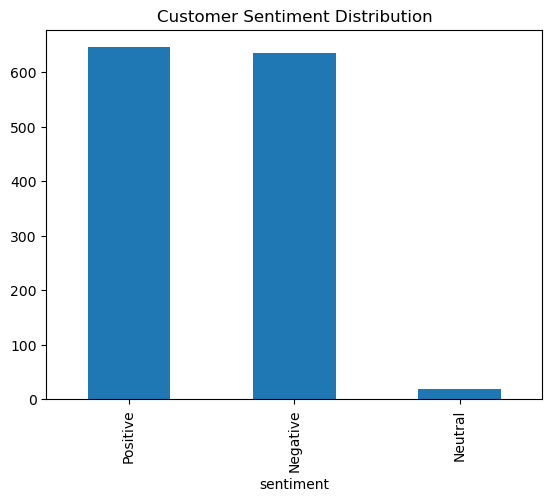

In [33]:
# Visualizing distribution
df['sentiment'].value_counts().plot(kind='bar', title='Customer Sentiment Distribution')

# Stage 4: Identifying the issue behind Negative Reviews

## Selected model: Latent Dirichlet Allocation (LDA)

In [35]:
# Importing required Libraries
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

In [36]:
# Filtering Negative reviews and store into new dataframe
negative_reviews = df.loc[df['sentiment']=='Negative', 'cleaned_reviews']
negative_reviews.head()

3    want warn everyone worst customer service expe...
4    paid business class travelling cairo london he...
5    plane extremely dirty chocolate smudged mine c...
6    overall journey bad however end baggage arriva...
8    always fly ba total shamble booked manchester ...
Name: cleaned_reviews, dtype: object

In [37]:
# Creating Vectorizer object along with proper parameters
vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=2,
    max_features=1000,
    ngram_range=(1, 2)
)

In [38]:
X = vectorizer.fit_transform(negative_reviews)

In [47]:
# Creating LDA model
lda = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    learning_method="batch",
    max_iter=20
)

In [48]:
# Run the model with Converted vectors
lda.fit(X)

LatentDirichletAllocation(max_iter=20, n_components=5, random_state=42)

In [49]:
feature_names = vectorizer.get_feature_names_out()

In [79]:
for topic_idx, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [feature_names[i] for i in top_indices]
    print(f"Topic {topic_idx}: {', '.join(top_words)}")

Topic 0: flight, ba, not, customer, service, no, day, british, airway, british airway
Topic 1: staff, ba, check, boarding, luggage, passenger, no, not, queue, baggage
Topic 2: ba, flight, london, no, via, hr, not, heathrow, service, said
Topic 3: seat, flight, not, no, class, ba, business, service, food, business class
Topic 4: flight, hour, not, london, delayed, no, bag, delay, heathrow, minute


In [51]:
# Assigning each negative review to its dominant topic
topic_probabilities = lda.transform(X)
dominant_topics = topic_probabilities.argmax(axis=1)

In [52]:
df['topic_id'] = pd.NA
df.head()

,title,reviews,cleaned_reviews,sentiment,sentiment_score,topic_id
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...,ba jan not appreciate unprofessional attitude ...,Positive,0.5013,<NA>
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...,not great experience could not check online tw...,Positive,0.8749,<NA>
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...,excited fly ba 'd not travelled long haul yr '...,Positive,0.4770,<NA>
3,“They never help us”,I just want to warn everyone of the worst cu...,want warn everyone worst customer service expe...,Negative,-0.8838,<NA>
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...,paid business class travelling cairo london he...,Negative,-0.9722,<NA>


In [53]:
df.loc[df['sentiment']=='Negative','topic_id'] = dominant_topics

In [56]:
df_n = df[df['sentiment']=='Negative']
df_n.head()

,title,reviews,cleaned_reviews,sentiment,sentiment_score,topic_id
3,“They never help us”,I just want to warn everyone of the worst cu...,want warn everyone worst customer service expe...,Negative,-0.8838,0
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...,paid business class travelling cairo london he...,Negative,-0.9722,3
5,"""Zero customer service""",The plane was extremely dirty with chocolate...,plane extremely dirty chocolate smudged mine c...,Negative,-0.9079,3
6,"""baggage arrival nearly took 1.5 hours""",Overall journey wasn’t bad however at the end...,overall journey bad however end baggage arriva...,Negative,-0.8750,4
8,"""airline is a total disgrace""",As always when I fly BA it was a total shamb...,always fly ba total shamble booked manchester ...,Negative,-0.9185,4


In [58]:
df_n['topic_id'].unique()

array([0, 3, 4, 1, 2], dtype=object)

In [60]:
df_n['topic_id'].value_counts()

topic_id
3    272
0    181
4    120
1     40
2     22
Name: count, dtype: int64

In [76]:
# random choices for sample check
import random
#random.seed(421)
samp_df = df_n.groupby('topic_id').sample(n=1)
samp_df

,title,reviews,cleaned_reviews,sentiment,sentiment_score,topic_id
238,"""I was left stranded at the airport""",Booked a flight return flight between London...,booked flight return flight london munich dece...,Negative,-0.4754,0
423,"""one excuse after another with BA these days""",Another dreadful mediocre experience with BA...,another dreadful mediocre experience ba malaga...,Negative,-0.6139,1
279,"""there is a race to the bottom""",It seems that there is a race to the bottom a...,seems race bottom amongst airline not even che...,Negative,-0.3655,2
435,"""have lost all patience with this airline""",I have always chosen to not make a big deal ...,always chosen not make big deal poor service d...,Negative,-0.9762,3
973,"""such a poor product""","Heathrow to Larnaca - departed on time, fligh...",heathrow larnaca departed time flight nearly f...,Negative,-0.7926,4


In [77]:
samp_list = samp_df[['topic_id','cleaned_reviews']].to_dict(orient='records')
samp_list

[{'topic_id': 0,
  'cleaned_reviews': 'booked flight return flight london munich december return flight cancelled booked british airway notified first change not second getting flight reinstated took multiple phone call occasion time needing find helpful representative british airway employee told even though cancelled flight not refund ticket tried charge change fee repeatedly calling back british airway reinstated flight make sure not get changed checked status ticket daily intact day time check flight gone airport staff british airway check counter not ba employee not help resolve problem no ba representative munich airport confirmation documentation british airway no value left stranded airport'},
 {'topic_id': 1,
  'cleaned_reviews': "another dreadful mediocre experience ba malaga time boarding bus remote stand no aircon flight wi fi erratic guest order food drink card payment system work gave ordering finally malaga held not allowed leave plane bag come first case 'we caused plan

In [80]:
# Mapping topic_id with corresponding names
topic_names = {
    0:'Customer Service',
    1:'Baggage Handling',
    2:'Food Quality',
    3:'Seat Comfort',
    4:'Flight Delays'
}

# Stage 5: Building the Recommendation Engine

In [78]:
# Mapping topic names with Recommendations
recommendations = {
    'Customer Service': 'Provide targeted staff training and monitor complaint resolution.',
    'Food Quality': 'Review catering quality and collect meal-specific ratings.',
    'Baggage Handling': 'Audit baggage tracking and handover processes.',
    'Seat Comfort': 'Analyze seat-related complaints and prioritize cabin improvements.',
    'Flight Delays': 'Review delay causes and improve proactive passenger notifications.'
}

In [81]:
# Built a function for Recommendation 
def recommend_action(sentiment, topic_id):
    if sentiment != "Negative" or pd.isna(topic_id):
        return "No complaint-specific action triggered."

    issue = topic_names.get(int(topic_id), "Other Issue")

    action = recommendations.get(
        issue,
        "Review the feedback and investigate the root cause."
    )

    return action

In [84]:
# Applying these recommedations to main data set
df['recommendation'] = df.apply(
    lambda row: recommend_action(row['sentiment'], row['topic_id']),
    axis = 1
)

In [85]:
df.head()

,title,reviews,cleaned_reviews,sentiment,sentiment_score,topic_id,recommendation
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...,ba jan not appreciate unprofessional attitude ...,Positive,0.5013,<NA>,No complaint-specific action triggered.
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...,not great experience could not check online tw...,Positive,0.8749,<NA>,No complaint-specific action triggered.
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...,excited fly ba 'd not travelled long haul yr '...,Positive,0.4770,<NA>,No complaint-specific action triggered.
3,“They never help us”,I just want to warn everyone of the worst cu...,want warn everyone worst customer service expe...,Negative,-0.8838,0,Provide targeted staff training and monitor co...
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...,paid business class travelling cairo london he...,Negative,-0.9722,3,Analyze seat-related complaints and prioritize...


# Stage 6: Combining the pipeline and save the models

In [86]:
import joblib

In [88]:
artifacts = {
    'vectorizer': vectorizer,
    'lda':lda,
    'topic_names':topic_names,
    'recommendations':recommendations
}

In [89]:
joblib.dump(artifacts, 'sentiment_artifacts.pkl')

['sentiment_artifacts.pkl']